In [1]:
# import libraries
import ssav_helpers
import ssav
from ssav_setup import *
from ssav_helpers import *
from ssav import *
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fftn, ifftn, fftfreq
from dataclasses import dataclass

In [2]:
L = np.array([2*np.pi, 2*np.pi])
N = np.array([128, 128])

Grid = generate_Grid(L, N, dim=2)

Time = TimeDomain(dt_min=1e-5, 
                  dt_max=0.01, 
                  t0=0, 
                  tf=30)

Para = Parameters(eps=0.06, 
                  alpha=0.0, 
                  beta=1.0,
                  delta=1e-8,
                  err_tol = np.array([1e-5, 1e-5]),
                  M=1.0, 
                  m=0.0, 
                  S=2.0, 
                  B=1.0, 
                  model="OK")

u = 2 * (
    -np.tanh(np.emath.sqrt((Grid.xx + 0.8)**2 + Grid.yy**2 - 1.4) / (1.5 * Para.eps))
    - np.tanh(np.emath.sqrt((Grid.xx - 1.7)**2 + Grid.yy**2 - 0.5) / (1.5 * Para.eps))
) + 3

u = np.real(u)

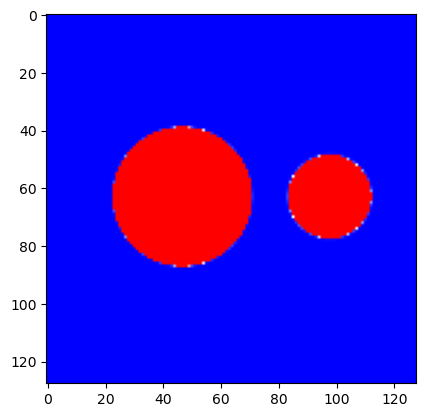

In [3]:
img = plt.imshow(u, cmap = 'bwr')
img.set_clim(-1,1)

plt.colorbar
plt.show()

In [4]:
Results = ssav(Grid, Time, Para, u, dim=2)

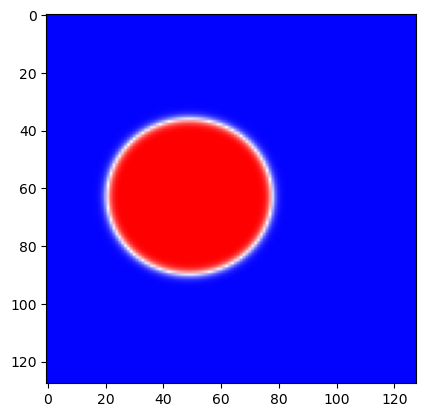

<bound method Figure.show of <Figure size 640x480 with 1 Axes>>

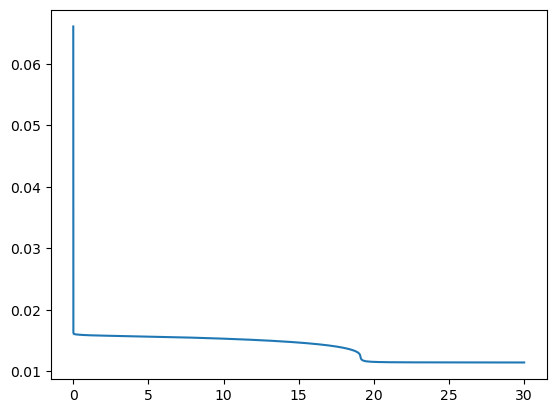

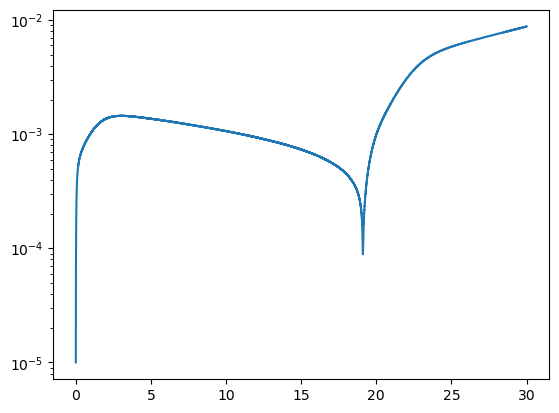

In [6]:
img = plt.imshow(Results.u, cmap = 'bwr')
img.set_clim(-1,1)

plt.colorbar
plt.show()

f1 = plt.figure()
plt.plot(Results.tt, Results.Eu)
f1.show

f2 = plt.figure()
plt.semilogy(np.array(Results.tt[1:]), Results.dt)
f2.show